Imports

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import timm
import os

/home/ajnur/Documents/Source/IUS/A.I/Project 2/.venv310/lib64/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Config

In [3]:
DATA_DIR = "dataset"
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 15
LR = 3e-4
NUM_CLASSES = 3

Cuda Check

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [5]:
torch.cuda.get_device_name(0)

'NVIDIA GeForce RTX 3060'

Transforms

In [6]:
train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(0.2, 0.2, 0.2, 0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

In [7]:
val_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

Dataset

In [8]:
train_ds = datasets.ImageFolder(os.path.join(DATA_DIR, "train"), transform=train_tfms)
val_ds   = datasets.ImageFolder(os.path.join(DATA_DIR, "val"), transform=val_tfms)

In [9]:
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

In [10]:
train_ds.classes

['Corner Reflector', 'Mavic 2 Pro', 'Phantom 4 Pro']

Model EfficientNet-B0 <br>
I chose it to reduce tranining time and stay within the specs of using CNN

In [11]:
class RadarEffNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = timm.create_model(
            "efficientnet_b0",
            pretrained=True,
            num_classes=0
        )

        in_features = self.backbone.num_features

        self.head = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(in_features, 256),
            nn.BatchNorm1d(256),
            nn.SiLU(),

            nn.Dropout(0.2),
            nn.Linear(256, NUM_CLASSES)
        )

    def forward(self, x):
        x = self.backbone(x)
        x = self.head(x)
        return x

In [12]:
model = RadarEffNet().to(device)

Loss and optimizer

In [13]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

Train and eval loop

In [14]:
def train_one_epoch():
    model.train()
    total_loss = 0

    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(train_loader)

In [15]:
def evaluate():
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)

            preds = torch.argmax(outputs, dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    return correct / total

Tranining

In [16]:
best_acc = 0

In [17]:
for epoch in range(EPOCHS):
    loss = train_one_epoch()
    acc = evaluate()
    scheduler.step()

    print(f"Epoch [{epoch+1}/{EPOCHS}] Loss: {loss:.4f} | Val Acc: {acc:.4f}")

    if acc > best_acc:
        best_acc = acc
        torch.save(model.state_dict(), "best_efficientnet_radar.pth")

print("Best Accuracy:", best_acc)

Epoch [1/15] Loss: 0.5264 | Val Acc: 0.9067
Epoch [2/15] Loss: 0.3175 | Val Acc: 0.9644
Epoch [3/15] Loss: 0.2796 | Val Acc: 0.9422
Epoch [4/15] Loss: 0.2648 | Val Acc: 0.9778
Epoch [5/15] Loss: 0.2395 | Val Acc: 0.9778
Epoch [6/15] Loss: 0.2287 | Val Acc: 0.9867
Epoch [7/15] Loss: 0.2252 | Val Acc: 0.9911
Epoch [8/15] Loss: 0.2406 | Val Acc: 0.9911
Epoch [9/15] Loss: 0.2121 | Val Acc: 0.9911
Epoch [10/15] Loss: 0.2093 | Val Acc: 0.9867
Epoch [11/15] Loss: 0.2107 | Val Acc: 0.9867
Epoch [12/15] Loss: 0.1986 | Val Acc: 0.9867
Epoch [13/15] Loss: 0.2073 | Val Acc: 0.9867
Epoch [14/15] Loss: 0.2063 | Val Acc: 0.9867
Epoch [15/15] Loss: 0.2027 | Val Acc: 0.9822
Best Accuracy: 0.9911111111111112


**Training Metrics & Visualizations**
The cells below will: (1) optionally run a training loop that records `train_losses` and `val_accs`, and (2) plot loss, validation accuracy, and a confusion matrix.
If you already have training history in `train_losses` / `val_accs`, the plotting cell will use them directly without re-training.

In [19]:
# Run training while recording history (safe to re-run)
# This will reuse your existing `train_one_epoch`, `evaluate`, `scheduler` and `model`
train_losses = globals().get('train_losses', [])
val_accs = globals().get('val_accs', [])
best_acc = globals().get('best_acc', 0)
# If train_losses already has entries and you don't want to retrain, set DO_TRAIN=False
DO_TRAIN = True
if DO_TRAIN:
    for epoch in range(EPOCHS):
        loss = train_one_epoch()
        acc = evaluate()
        scheduler.step()

        train_losses.append(loss)
        val_accs.append(acc)

        print(f"Epoch [{epoch+1}/{EPOCHS}] Loss: {loss:.4f} | Val Acc: {acc:.4f}")

        if acc > best_acc:
            best_acc = acc
            torch.save(model.state_dict(), "best_efficientnet_radar.pth")

    print('Training complete. Best Acc:', best_acc)

# expose into globals for plotting cells
globals()['train_losses'] = train_losses
globals()['val_accs'] = val_accs
globals()['best_acc'] = best_acc

Epoch [1/15] Loss: 0.2071 | Val Acc: 0.9867
Epoch [2/15] Loss: 0.1934 | Val Acc: 0.9867
Epoch [3/15] Loss: 0.2061 | Val Acc: 0.9867
Epoch [4/15] Loss: 0.1989 | Val Acc: 0.9867
Epoch [5/15] Loss: 0.1976 | Val Acc: 0.9822
Epoch [6/15] Loss: 0.1941 | Val Acc: 0.9867
Epoch [7/15] Loss: 0.2150 | Val Acc: 0.9867
Epoch [8/15] Loss: 0.2051 | Val Acc: 0.9911
Epoch [9/15] Loss: 0.2187 | Val Acc: 0.9689
Epoch [10/15] Loss: 0.2107 | Val Acc: 0.9911
Epoch [11/15] Loss: 0.2117 | Val Acc: 0.9778
Epoch [12/15] Loss: 0.2014 | Val Acc: 0.9822
Epoch [13/15] Loss: 0.2008 | Val Acc: 0.9867
Epoch [14/15] Loss: 0.2002 | Val Acc: 0.9644
Epoch [15/15] Loss: 0.2197 | Val Acc: 0.9867
Training complete. Best Acc: 0.9911111111111112


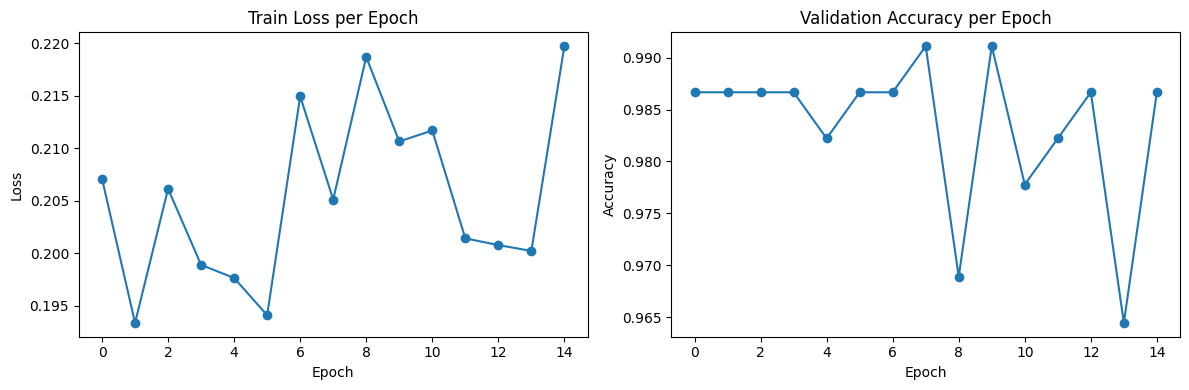

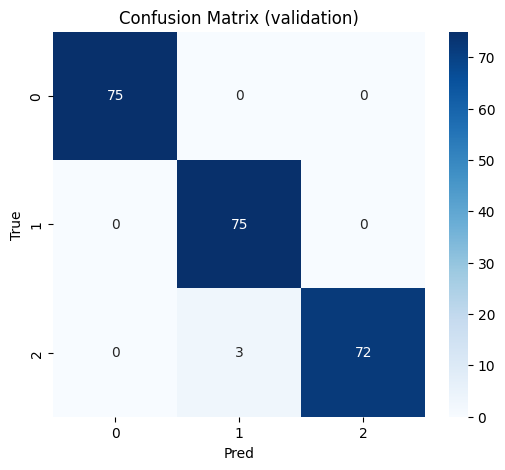

Classification report:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        75
           1     0.9615    1.0000    0.9804        75
           2     1.0000    0.9600    0.9796        75

    accuracy                         0.9867       225
   macro avg     0.9872    0.9867    0.9867       225
weighted avg     0.9872    0.9867    0.9867       225



In [20]:
# Plots: loss, validation accuracy, and confusion matrix
import sys, subprocess
try:
    import matplotlib.pyplot as plt
    import seaborn as sns
    from sklearn.metrics import confusion_matrix, classification_report
except Exception:
    print('Missing plotting/metrics packages, installing scikit-learn, matplotlib, seaborn...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'scikit-learn', 'matplotlib', 'seaborn'])
    import matplotlib.pyplot as plt
    import seaborn as sns
    from sklearn.metrics import confusion_matrix, classification_report

# Plot training loss and validation accuracy if available
train_losses = globals().get('train_losses', [])
val_accs = globals().get('val_accs', [])
plt.figure(figsize=(12,4))
if train_losses:
    plt.subplot(1,2,1)
    plt.plot(train_losses, marker='o')
    plt.title('Train Loss per Epoch')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
else:
    print('No `train_losses` found - run the training cell to populate it.')

if val_accs:
    plt.subplot(1,2,2)
    plt.plot(val_accs, marker='o')
    plt.title('Validation Accuracy per Epoch')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
plt.tight_layout()
plt.show()

# Confusion matrix on validation set
y_true = []
y_pred = []
model.eval()
with torch.no_grad():
    for imgs, labels in val_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()
        y_pred.extend(preds)
        y_true.extend(labels.numpy())

if len(y_true)>0:
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title('Confusion Matrix (validation)')
    plt.ylabel('True')
    plt.xlabel('Pred')
    plt.show()

    print('Classification report:')
    print(classification_report(y_true, y_pred, digits=4))
else:
    print('Validation set appears empty or predictions failed - check `val_loader`.')

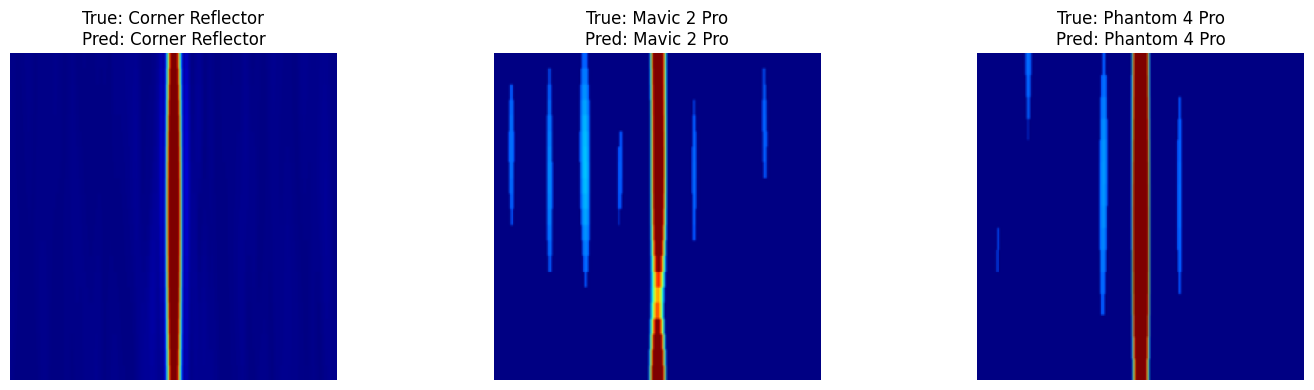

In [22]:
# Show one validation prediction per class
import matplotlib.pyplot as plt
import numpy as np
class_names = val_ds.classes if 'val_ds' in globals() else train_ds.classes
examples = {}
for idx in range(len(val_ds)):
    _, label = val_ds[idx]
    if label not in examples:
        examples[label] = idx
    if len(examples) == len(class_names):
        break

if not examples:
    print('No validation examples found.')
else:
    indices = [examples[label] for label in sorted(examples)]
    images = []
    labels_true = []
    for idx in indices:
        img, label = val_ds[idx]
        images.append(img)
        labels_true.append(label)

    batch = torch.stack(images).to(device)
    model.eval()
    with torch.no_grad():
        outputs = model(batch)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    fig, axes = plt.subplots(1, len(images), figsize=(5 * len(images), 4))
    if len(images) == 1:
        axes = [axes]

    for ax, img, true_label, pred_label in zip(axes, images, labels_true, preds):
        img = img.cpu().permute(1, 2, 0).numpy()
        img = (img * std) + mean
        img = np.clip(img, 0, 1)
        ax.imshow(img)
        ax.set_title(f"True: {class_names[true_label]}\nPred: {class_names[pred_label]}")
        ax.axis('off')

    plt.tight_layout()
    plt.show()